# Лабораторная работа 4. Зависимость коэффициента липофильности от структуры молекул (двухслойный перцептрон)

Модель: $\log P = b^{(2)} + (w^{(2)})^T\,\mathrm{ReLU}(W^{(1)}x + b^{(1)})$. Обучение — полнопакетный градиентный спуск, реализованный вручную на `numpy` (прямой и обратный проход, проверка градиента конечными разностями). `scikit-learn` используется для сравнения.

## 1. Данные и подготовка

In [9]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, time
from scipy import stats
pd.set_option("display.width", 200)
df = pd.read_csv("lipo.csv"); df["Вещество"] = df["Вещество"].str.strip()
feat = list(df.columns[2:]); y = df["logP"].values.astype(float); X = df[feat].values.astype(float); n, d = X.shape
print("Выборка:", df.shape, "| пропусков:", int(df.isna().sum().sum()))
# вещества с полностью одинаковым набором дескрипторов (изомеры) — неустранимая ошибка для любой модели
dup = df[df.duplicated(feat, keep=False)].sort_values(feat)[["Вещество", "logP"]]
print("Строк с неуникальным вектором признаков:", len(dup)); dup

Выборка: (82, 26) | пропусков: 0
Строк с неуникальным вектором признаков: 7


,Вещество,logP
62,Sulfadimidine,0.89
71,Sulfisomidine,-0.33
65,Sulfamethoxydiazine,0.41
66,Sulfamethoxypyridazine,0.32
67,Sulfametopyrazine,0.70
61,Sulfadimethoxine,1.63
63,Sulfadoxine,0.70


In [10]:
# Признаки имеют разный масштаб (PSA ~ 0..200, C ~ 2..40, группы ~ 0..1): без стандартизации градиентный спуск плохо сходится
mu, sd = X.mean(0), X.std(0); my, sy = y.mean(), y.std()
Xs = (X - mu)/sd; ys = (y - my)/sy
print("После стандартизации: mean ≈", Xs.mean().round(12), ", std ≈", Xs.std(0).mean().round(3))

После стандартизации: mean ≈ -0.0 , std ≈ 1.0


## 2. Реализация перцептрона и градиентного спуска

Функция потерь $L=\frac{1}{2n}\sum_i(\hat y_i-y_i)^2$ (на стандартизованном $y$, поэтому $L=\tfrac12\mathrm{MSE}$; в единицах logP: $\mathrm{RMSE}=\sigma_y\sqrt{2L}$). Градиенты: $\delta_i=(\hat y_i-y_i)/n$, $\partial L/\partial w^{(2)}=A^T\delta$, $\partial L/\partial b^{(2)}=\sum\delta_i$, $\partial L/\partial W^{(1)}=[(\delta w^{(2)T})\odot \mathbb 1_{Z>0}]^TX$.

**Критерий остановки:** $\|\nabla L\|<\delta$ или достигнут предел итераций.

In [11]:
def init(h, d, seed=0):
    r = np.random.default_rng(seed)
    return dict(W1=r.normal(0, np.sqrt(2/d), (h, d)), b1=np.zeros(h), w2=r.normal(0, np.sqrt(1/h), h), b2=0.0)

def forward(P, Xm):
    Z = Xm @ P["W1"].T + P["b1"]; A = np.maximum(Z, 0)
    return Z, A, A @ P["w2"] + P["b2"]

def loss_grad(P, Xm, yv):
    m = len(yv); Z, A, yh = forward(P, Xm); r = yh - yv; g = r/m
    G = np.outer(g, P["w2"]) * (Z > 0)
    return 0.5*np.mean(r**2), dict(W1=G.T @ Xm, b1=G.sum(0), w2=A.T @ g, b2=g.sum())

def gnorm(gr): return np.sqrt(sum(np.sum(v**2) for v in gr.values()))

def train_gd(Xm, yv, h, eps, delta, max_iter, decay=0.0, seed=0):
    """Градиентный спуск; шаг eps_k = eps/(1+decay*k) (decay=0 — постоянная скорость)."""
    P = init(h, Xm.shape[1], seed); hist = []
    for k in range(1, max_iter+1):
        L, gr = loss_grad(P, Xm, yv); hist.append(L)
        if gnorm(gr) < delta: return P, np.array(hist), k, True, gnorm(gr)
        step = eps/(1+decay*k)
        for key in P: P[key] = P[key] - step*gr[key]
    return P, np.array(hist), max_iter, False, gnorm(gr)

def metrics(P, Xm, yv_raw):
    yh = forward(P, Xm)[2]*sy + my; rmse = np.sqrt(np.mean((yh-yv_raw)**2))
    return rmse, 1 - np.sum((yh-yv_raw)**2)/np.sum((yv_raw-yv_raw.mean())**2)

# проверка градиента конечными разностями
P = init(4, d, seed=1); _, gr = loss_grad(P, Xs, ys); err = 0
for key in ["W1", "b1", "w2"]:
    idx = tuple(np.random.default_rng(0).integers(0, s_) for s_ in P[key].shape)
    Pp = {k_: np.copy(v) if isinstance(v, np.ndarray) else v for k_, v in P.items()}; Pp[key][idx] += 1e-6
    num = (loss_grad(Pp, Xs, ys)[0] - loss_grad(P, Xs, ys)[0])/1e-6
    err = max(err, abs(num - gr[key][idx])); 
print("Макс. расхождение аналитического и численного градиента:", err)

Макс. расхождение аналитического и численного градиента: 1.672204168190472e-07


## 3. Обучение моделей с 2, 4, 8, 16, 32 нейронами

Фиксируем скорость обучения $\varepsilon = 0{,}05$ и точность $\delta = 10^{-4}$ (норма градиента), предел — 100 000 итераций.

In [12]:
EPS, DELTA, MAXIT = 0.05, 1e-4, 100_000
sizes = [2, 4, 8, 16, 32]; fits = {}; rows = []
for h in sizes:
    t0 = time.time(); P, H, it, ok, gn = train_gd(Xs, ys, h, EPS, DELTA, MAXIT)
    rmse, r2 = metrics(P, Xs, y); fits[h] = (P, H)
    rows.append(dict(нейронов=h, параметров=h*d+2*h+1, итераций=it, сошёлся=("да" if ok else "нет"), норма_градиента=gn, L_конечная=H[-1], RMSE_logP=rmse, R2=r2, время_с=round(time.time()-t0, 1)))
res_const = pd.DataFrame(rows).set_index("нейронов"); res_const

,параметров,итераций,сошёлся,норма_градиента,L_конечная,RMSE_logP,R2,время_с
нейронов,,,,,,,,
2,53,100000,нет,0.102657,0.047272,0.490008,0.905305,7.1
4,105,100000,нет,0.313045,0.009863,0.226191,0.979822,7.3
8,209,100000,нет,0.016768,0.003027,0.123897,0.993946,7.9
16,417,49212,да,0.000100,0.003023,0.123816,0.993954,4.1
32,833,62560,да,0.000100,0.003025,0.123849,0.993951,5.9


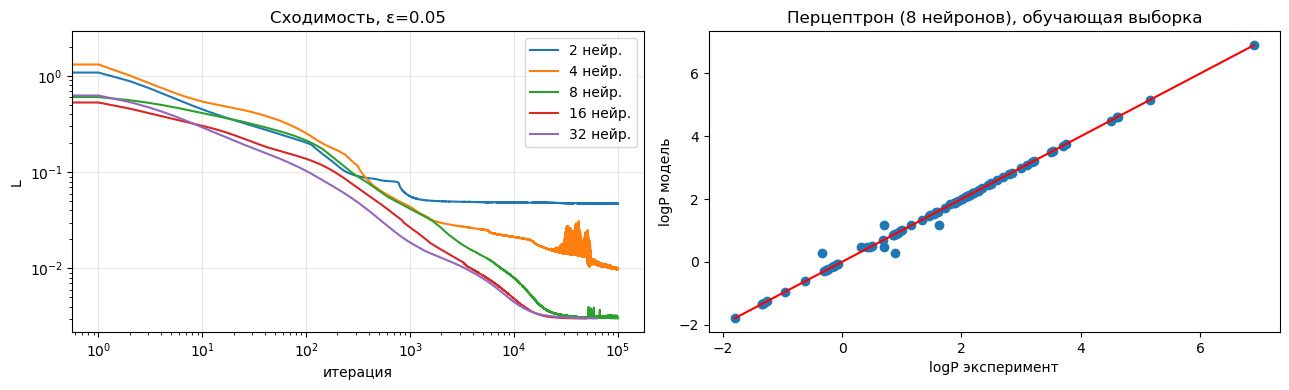

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for h in sizes: ax[0].semilogy(fits[h][1], label=f"{h} нейр."); 
ax[0].set_xscale("log"); ax[0].set_xlabel("итерация"); ax[0].set_ylabel("L"); ax[0].set_title(f"Сходимость, ε={EPS}"); ax[0].legend(); ax[0].grid(alpha=.3)
P8 = fits[8][0]; yh = forward(P8, Xs)[2]*sy+my
ax[1].scatter(y, yh); lim = [y.min(), y.max()]; ax[1].plot(lim, lim, "r"); ax[1].set_xlabel("logP эксперимент"); ax[1].set_ylabel("logP модель"); ax[1].set_title("Перцептрон (8 нейронов), обучающая выборка")
plt.tight_layout()

## 4. Эксперименты со скоростью обучения

Сравниваем: (а) постоянный шаг $\varepsilon=0{,}05$ (п. 3); (б) постоянный меньший шаг $\varepsilon=0{,}01$; (в) убывающий шаг $\varepsilon_k=\varepsilon_0/(1+\gamma k)$ с $\varepsilon_0=0{,}2$, $\gamma=10^{-3}$. Предел итераций тот же.

In [14]:
variants = {"const 0.05": (0.05, 0.0), "const 0.01": (0.01, 0.0), "decay 0.2/(1+1e-3·k)": (0.2, 1e-3)}
rows = []; hists = {}
for h in sizes:
    for name, (e0, g0) in variants.items():
        if name == "const 0.05":      # уже посчитано в п. 3
            H = fits[h][1]; hists[(h, name)] = H; r_ = res_const.loc[h]
            rows.append(dict(нейронов=h, шаг=name, итераций=int(r_["итераций"]), сошёлся=r_["сошёлся"], норма_градиента=r_["норма_градиента"], L_конечная=H[-1], RMSE_logP=r_["RMSE_logP"])); continue
        P, H, it, ok, gn = train_gd(Xs, ys, h, e0, DELTA, MAXIT, decay=g0); hists[(h, name)] = H
        rows.append(dict(нейронов=h, шаг=name, итераций=it, сошёлся=("да" if ok else "нет"), норма_градиента=gn, L_конечная=H[-1], RMSE_logP=metrics(P, Xs, y)[0]))
res_lr = pd.DataFrame(rows).set_index(["нейронов", "шаг"]); res_lr

итераций сошёлся  норма_градиента  L_конечная  RMSE_logP
нейронов шаг                                                                           
2        const 0.05              100000     нет         0.102657    0.047272   0.490008
         const 0.01              100000     нет         0.026995    0.048003   0.493377
         decay 0.2/(1+1e-3·k)    100000     нет         0.045826    0.048156   0.494171
4        const 0.05              100000     нет         0.313045    0.009863   0.226191
         const 0.01              100000     нет         0.027019    0.016283   0.287379
         decay 0.2/(1+1e-3·k)    100000     нет         0.036745    0.041696   0.459838
8        const 0.05              100000     нет         0.016768    0.003027   0.123897
         const 0.01              100000     нет         0.005265    0.003770   0.138264
         decay 0.2/(1+1e-3·k)    100000     нет         0.009742    0.004430   0.149890
16       const 0.05               49212      да         0.000100    0.003023   0.123816
         const 0.01              100000     нет         0.001033    0.003189   0.127170
         decay 0.2/(1+1e-3·k)    100000     нет         0.001288    0.003257   0.128514
32       const 0.05               62560      да         0.000100    0.003025   0.123849
         const 0.01              100000     нет         0.000896    0.003257   0.128509
         decay 0.2/(1+1e-3·k)    100000     нет         0.003468    0.003282   0.129009

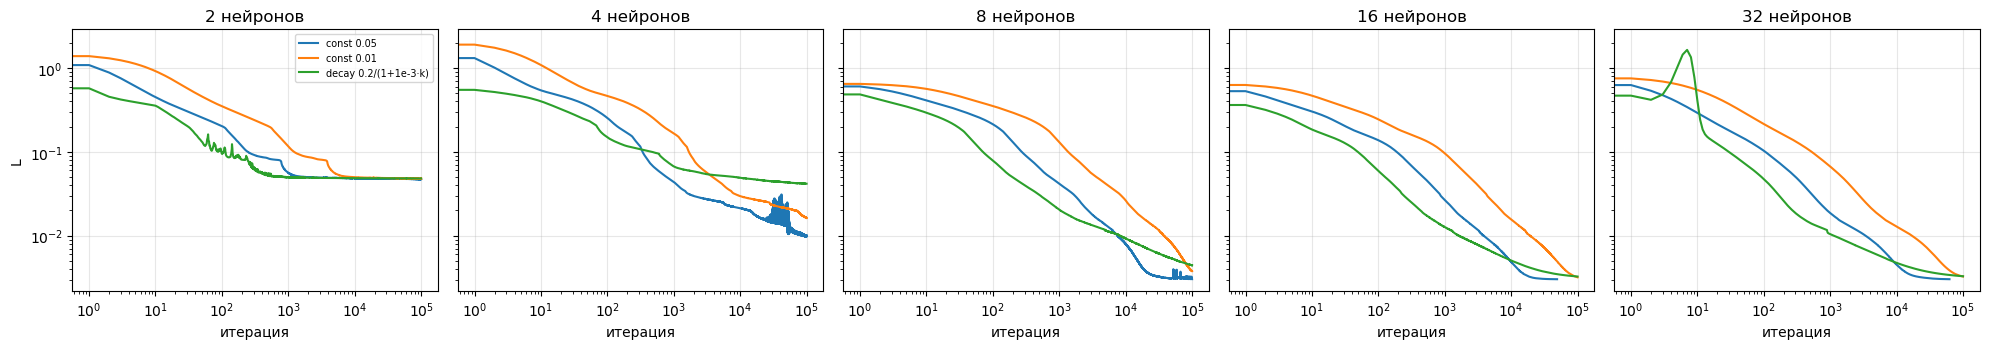

In [15]:
fig, ax = plt.subplots(1, 5, figsize=(20, 3.6), sharey=True)
for a, h in zip(ax, sizes):
    for name in variants: a.semilogy(hists[(h, name)], label=name)
    a.set_xscale("log"); a.set_title(f"{h} нейронов"); a.set_xlabel("итерация"); a.grid(alpha=.3)
ax[0].set_ylabel("L"); ax[0].legend(fontsize=7); plt.tight_layout()

## 5. Сравнение с `scikit-learn` (MLPRegressor)

Та же архитектура (один скрытый слой, ReLU), те же стандартизованные данные, `alpha=0` (без регуляризации). Решатели: `sgd` (аналог нашего метода, но с мини-батчами) и `lbfgs`.

In [16]:
from sklearn.neural_network import MLPRegressor
import warnings; warnings.filterwarnings("ignore")
rows = []
for h in sizes:
    for solver, kw in [("sgd", dict(learning_rate_init=0.05, batch_size=n, max_iter=20000, tol=1e-9, n_iter_no_change=1000)), ("lbfgs", dict(max_iter=5000, tol=1e-9))]:
        m = MLPRegressor(hidden_layer_sizes=(h,), activation="relu", solver=solver, alpha=0.0, random_state=0, **kw).fit(Xs, ys)
        yh = m.predict(Xs)*sy+my
        rows.append(dict(нейронов=h, решатель=solver, итераций=m.n_iter_, RMSE_logP=np.sqrt(np.mean((yh-y)**2)), R2=1-np.sum((yh-y)**2)/np.sum((y-y.mean())**2)))
res_sk = pd.DataFrame(rows).set_index(["нейронов", "решатель"])
cmp_ = res_sk.join(res_const[["RMSE_logP", "R2"]].rename(columns=lambda c: c+"_наш"), on="нейронов"); cmp_

итераций  RMSE_logP        R2  RMSE_logP_наш    R2_наш
нейронов решатель                                                        
2        sgd           3803   0.560976  0.875889       0.490008  0.905305
         lbfgs          772   0.438118  0.924298       0.490008  0.905305
4        sgd           9854   0.187086  0.986196       0.226191  0.979822
         lbfgs         1526   0.174376  0.988008       0.226191  0.979822
8        sgd           3861   0.146727  0.991509       0.123897  0.993946
         lbfgs          266   0.128202  0.993518       0.123897  0.993946
16       sgd           6512   0.126612  0.993678       0.123816  0.993954
         lbfgs          569   0.123743  0.993961       0.123816  0.993954
32       sgd           9257   0.123983  0.993938       0.123849  0.993951
         lbfgs          473   0.123741  0.993961       0.123849  0.993951

## 6. Адекватность: обучение vs обобщение

На обучающей выборке перцептрон с десятками параметров на 82 веществ почти интерполирует данные, поэтому настоящее качество оценим 5-fold кросс-валидацией (одни и те же разбиения для всех моделей, 2 повтора, по 10 000 итераций), и сравним с линейной регрессией из лабораторной 3.

In [17]:
def cv_all(reps=2, folds=5, max_iter=10_000):
    out = {f"MLP-{h}": [] for h in sizes}; out["Линейная регрессия"] = []; out["MLP-8 + убыв. шаг"] = []
    for r in range(reps):
        idx = np.random.default_rng(100+r).permutation(n)
        preds = {k_: np.zeros(n) for k_ in out}
        for f in np.array_split(idx, folds):
            tr = np.setdiff1d(idx, f)
            m_, s_ = X[tr].mean(0), X[tr].std(0); s_[s_ == 0] = 1          # стандартизация только по обучающей части
            Xt, Xv = (X[tr]-m_)/s_, (X[f]-m_)/s_; mt, st = y[tr].mean(), y[tr].std(); yt = (y[tr]-mt)/st
            for h in sizes:
                P = train_gd(Xt, yt, h, EPS, DELTA, max_iter)[0]; preds[f"MLP-{h}"][f] = forward(P, Xv)[2]*st+mt
            P = train_gd(Xt, yt, 8, 0.2, DELTA, max_iter, decay=1e-3)[0]; preds["MLP-8 + убыв. шаг"][f] = forward(P, Xv)[2]*st+mt
            A1 = np.column_stack([np.ones(len(tr)), X[tr]]); bb = np.linalg.lstsq(A1, y[tr], rcond=None)[0]
            preds["Линейная регрессия"][f] = np.column_stack([np.ones(len(f)), X[f]]) @ bb
        for k_ in out: out[k_].append(np.sqrt(np.mean((preds[k_]-y)**2)))
    return pd.DataFrame({k_: [np.mean(v), np.std(v)] for k_, v in out.items()}, index=["RMSE CV (среднее)", "± std"]).T
t0 = time.time(); cv = cv_all(); print("время, с:", round(time.time()-t0)); cv.round(3)

время, с: 42


,RMSE CV (среднее),± std
MLP-2,1.703,0.010
MLP-4,1.488,0.095
MLP-8,2.295,0.038
MLP-16,1.634,0.109
MLP-32,1.677,0.325
Линейная регрессия,1.075,0.005
MLP-8 + убыв. шаг,2.147,0.033


In [18]:
# Сводная таблица: обучение против CV
summary = pd.DataFrame({"RMSE обучение": [res_const.loc[h, "RMSE_logP"] for h in sizes], "RMSE CV": [cv.loc[f"MLP-{h}", "RMSE CV (среднее)"] for h in sizes]}, index=[f"MLP-{h}" for h in sizes])
lin_train = np.sqrt(np.mean((y - np.column_stack([np.ones(n), X]) @ np.linalg.lstsq(np.column_stack([np.ones(n), X]), y, rcond=None)[0])**2))
summary.loc["Линейная регрессия"] = [lin_train, cv.loc["Линейная регрессия", "RMSE CV (среднее)"]]
summary["R2 обучение"] = 1 - summary["RMSE обучение"]**2/y.var()
print("Разброс logP (std):", round(y.std(), 3)); summary.round(3)

Разброс logP (std): 1.592


,RMSE обучение,RMSE CV,R2 обучение
MLP-2,0.490,1.703,0.905
MLP-4,0.226,1.488,0.980
MLP-8,0.124,2.295,0.994
MLP-16,0.124,1.634,0.994
MLP-32,0.124,1.677,0.994
Линейная регрессия,0.641,1.075,0.838


### Попытка улучшить обобщение: L2-регуляризация (sklearn)

Перцептрон без регуляризации переобучается; штраф $\alpha\|W\|^2$ ограничивает веса. Стандартизация внутри каждого фолда (Pipeline), те же разбиения, 8 нейронов, `lbfgs`.

In [19]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold, cross_val_predict
rows = []
for h in [8, 32]:
    for alpha in [0, 0.1, 1, 3, 10, 30]:
        rm = []
        for r in range(2):
            mdl = make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=(h,), solver="lbfgs", alpha=alpha, max_iter=3000, random_state=r))
            p = cross_val_predict(mdl, X, y, cv=KFold(5, shuffle=True, random_state=100+r)); rm.append(np.sqrt(np.mean((p-y)**2)))
        rows.append(dict(нейронов=h, alpha=alpha, RMSE_CV=np.mean(rm)))
reg = pd.DataFrame(rows).pivot(index="alpha", columns="нейронов", values="RMSE_CV")
print("Для сравнения: линейная регрессия RMSE CV =", round(cv.loc["Линейная регрессия", "RMSE CV (среднее)"], 3)); reg.round(3)

Для сравнения: линейная регрессия RMSE CV = 1.075


нейронов,8,32
alpha,,
0.0,1.804,1.512
0.1,1.105,1.090
1.0,1.007,0.990
3.0,1.051,1.029
10.0,1.096,1.102
30.0,1.133,1.137


## 7. Вклад регрессоров

Перцептрон нелинеен, поэтому коэффициентов-аналогов нет. Используем *перестановочную важность*: рост RMSE на всей выборке при случайном перемешивании одного столбца (усреднение по 30 перестановкам и по 5 инициализациям модели с 8 нейронами), и сопоставляем с модулем стандартизованных коэффициентов линейной регрессии.

In [20]:
rng = np.random.default_rng(0); imp = np.zeros(d); nm = 5
for seed in range(nm):
    P = train_gd(Xs, ys, 8, EPS, DELTA, 20_000, seed=seed)[0]; base = np.sqrt(np.mean((forward(P, Xs)[2]*sy+my - y)**2))
    for j in range(d):
        v = 0
        for _ in range(30):
            Xp = Xs.copy(); Xp[:, j] = rng.permutation(Xp[:, j]); v += np.sqrt(np.mean((forward(P, Xp)[2]*sy+my - y)**2)) - base
        imp[j] += v/30/nm
A1 = np.column_stack([np.ones(n), X]); bl = np.linalg.lstsq(A1, y, rcond=None)[0]
lin_std = np.abs(bl[1:]*X.std(0, ddof=1)/y.std(ddof=1))
imp_df = pd.DataFrame({"перест. важность MLP (ΔRMSE)": imp, "|станд. коэфф.| лин.": lin_std}, index=feat).sort_values("перест. важность MLP (ΔRMSE)", ascending=False)
rho = stats.spearmanr(imp_df.iloc[:, 0], imp_df.iloc[:, 1])
print(f"Ранговая корреляция Спирмена важностей MLP и линейной модели: {rho.statistic:.2f} (p={rho.pvalue:.3f})")
imp_df.round(3)

Ранговая корреляция Спирмена важностей MLP и линейной модели: 0.58 (p=0.003)


,перест. важность MLP (ΔRMSE),|станд. коэфф.| лин.
PSA,4.466,1.741
HBA2,4.038,2.159
HBA1,3.619,1.071
C,2.279,2.262
MR,1.758,1.007
HBD,1.707,0.025
RSO2NR,1.615,0.177
AROMATIC,1.260,0.128
RINGS,1.032,0.335
RNH2,0.981,0.044


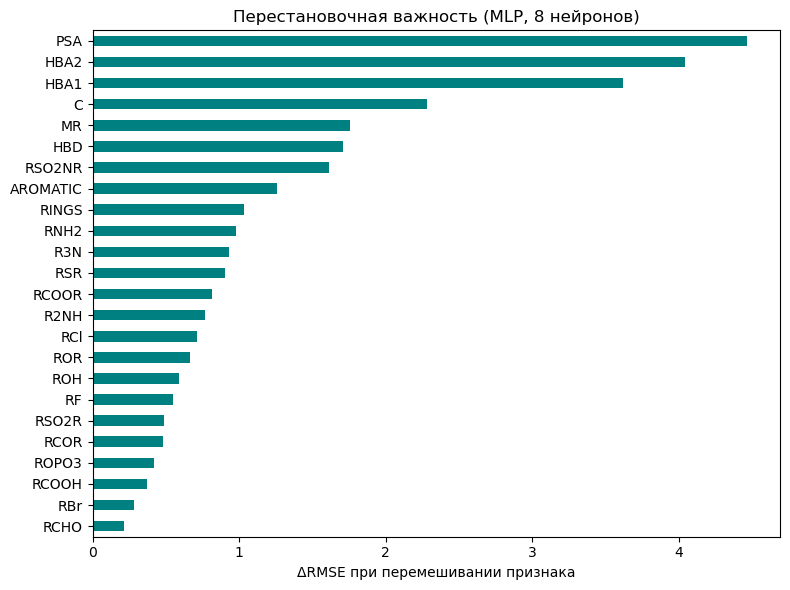

In [21]:
fig, ax = plt.subplots(figsize=(8, 6)); imp_df.iloc[::-1, 0].plot.barh(ax=ax, color="teal"); ax.set_xlabel("ΔRMSE при перемешивании признака"); ax.set_title("Перестановочная важность (MLP, 8 нейронов)"); plt.tight_layout()

## 8. Выводы

**Сходимость градиентного спуска** ($\varepsilon=0{,}05$, $\delta=10^{-4}$ по норме градиента, лимит 100 000 итераций). Сошлись только модели с 16 нейронами (49 212 итераций) и 32 нейронами (62 560 итераций). Модели с 2, 4 и 8 нейронами за 100 000 итераций критерий не выполнили: для них норма градиента остаётся выше $\delta$ (у 2 и 4 нейронов — из-за того, что шаг велик для «узкой» сети, и функция потерь колеблется; у 8 нейронов функция потерь уже почти не меняется, но градиент ещё не достиг $10^{-4}$). Чем шире скрытый слой, тем легче и быстрее спуск находит хорошее решение (ландшафт потерь становится более «проходимым»). Предельная ошибка на обучении (RMSE ≈ 0,124 по logP, $R^2\approx 0{,}994$) одинакова для 8, 16 и 32 нейронов: это не случайность, а **неустранимый порог** — в выборке есть 7 сульфаниламидов с идентичным вектором дескрипторов, но разными logP (от −0,33 до 1,63), и никакая модель, зависящая только от дескрипторов, не может их различить.

**Скорость обучения.** Уменьшение постоянного шага до 0,01 и убывающий шаг $0{,}2/(1+10^{-3}k)$ в нашем бюджете итераций **не ускорили сходимость, а ухудшили её**: ни одна из 10 комбинаций не уложилась в $\delta$, а финальные потери хуже, чем при $\varepsilon=0{,}05$ (особенно для 4 нейронов: 0,042 против 0,010), потому что шаг успевает слишком сильно упасть. Убывающий шаг гасит колебания, но требует более длительного обучения либо более медленного затухания $\gamma$. Для достижения строгого $\delta$ при постоянном $\varepsilon$ пришлось бы либо сильно увеличить число итераций, либо использовать адаптивные методы (Adam, L-BFGS).

**Сравнение с `scikit-learn`.** Для 8, 16, 32 нейронов результаты на обучающей выборке совпадают с нашей реализацией (RMSE 0,124–0,127), что подтверждает корректность ручного метода. Для 2 и 4 нейронов результат зависит от инициализации и решателя (L-BFGS находит лучший минимум, чем SGD и наш спуск при 2 нейронах: RMSE 0,448 против 0,490), так как задача невыпуклая. Решатель L-BFGS сходится за 400–1200 итераций против десятков тысяч у градиентного спуска.

**Адекватность модели.** На обучающей выборке перцептрон выглядит отлично ($R^2$ до 0,994 против 0,838 у линейной регрессии), но это переобучение: при 5-fold кросс-валидации RMSE равен 1,5–2,3, что **хуже линейной регрессии (1,08) и сравнимо или хуже простого предсказания среднего** (σ(logP) = 1,59). Причина — 209–833 параметра на 82 наблюдения без регуляризации. Следовательно, **использование двухслойного перцептрона в таком виде для описания зависимости logP от структуры неадекватно** (в смысле предсказательной способности). L2-регуляризация радикально улучшает обобщение (см. таблицу выше): при $\alpha=1$ CV-ошибка падает до ≈1,0 (8 нейронов) и ≈0,99 (32 нейрона), т.е. чуть лучше линейной регрессии (1,08). Выигрыш небольшой: регуляризованный перцептрон адекватен, но ненамного точнее линейной модели; без регуляризации — неадекватен.

**Вклад регрессоров.** По перестановочной важности наибольший вклад вносят PSA, HBA2, HBA1, C и MR — те же пять признаков, что лидируют по стандартизованным коэффициентам линейной модели (ранговая корреляция Спирмена 0,58, $p=0{,}003$). Это согласуется с физикой липофильности: размер молекулы (C, MR) повышает logP, полярность и способность к водородным связям (PSA, HBA, HBD) понижают его. Наименьший вклад — у редких групп RCHO, RBr, ROPO3, RCOOH, RCOR, RF (в выборке они встречаются в 1–7 веществах, и модель не может выучить их эффект). Оговорка: абсолютные значения ΔRMSE у переобученной сети завышены, так как перемешанные признаки уводят её в области, где она никогда не обучалась; поэтому надёжнее интерпретировать только ранги. Сеть приписывает заметную важность HBD и RSO2NR, которых нет в линейной модели — но, учитывая плохую CV-ошибку, это может быть подгонкой под шум.

**Сопоставление с линейной регрессией (лаб. 3).** На обучении перцептрон лучше (RMSE 0,12–0,22 против 0,64), на новых данных — хуже (1,5–2,3 против 1,08). Линейная модель объяснима и устойчивее при малой выборке; обе модели сходятся в выборе главных признаков.

## Приложение. Использование генеративного ИИ (промт)

Задание выполнено с помощью Claude (Anthropic). Промт пользователя:

> Сделай эти две лаб работы. На выходе должно быть два notebook (блокнот с кодом и всеми результатами работы программы согласно техническому заданию) для каждой лаб работы соответственно. Также здесь некоторые пожелания от преподавателя (Совсем забыл сказать: генеративным ИИ можно пользоваться для всего кроме тестов, контрактов (если они будут) и документации. Если будете пользоваться, приложите к отчёту промты.) Мне надо чтобы ты сделал все за меня, так что просто учти это... Уложись в рамках лимита пожалуйста
> (к промту были приложены файлы lab3.pdf, lab4.pdf, lipo.csv)